# 08. 실험 4b — 상한 확인: 정답 어긋남으로 옮겨 주면 탄소 오차가 줄어드는가

**한 줄 요약:** 05와 똑같은 LORO(같은 표본·같은 RF)를 다시 돌리되, 평가 지역을 옮기는 기준을 **라벨로 잰 정답 어긋남**으로 바꾼다(일부러 반칙). 이렇게 해도 탄소 오차가 안 줄면, 어긋남을 어떻게 재든 지금의 보정 방식(shift)으로는 안 된다는 뜻이다.

**쉬운 설명**
- 지금까지: "어긋남을 어떻게 잴까"(전체 중앙값 → 봉우리)를 바꿔 봄 → 둘 다 지역이 둘로 갈림
- 이번: 정답을 알려 주고 옮긴다 = 정확한 도수의 안경을 씌워 본다
- 잘 보이면(오차 감소) → α는 살아 있다. 남은 문제는 "정답을 라벨 없이/조금으로 맞히기"
- 안 보이면 → 문제는 재는 법이 아니라 옮기는 방식. α(shift) 방향을 접고 정리

**옮기는 기준만 바뀐다 (7-2절 `shift()` 그대로)**

| | 위치 기준 | 크기 기준 |
|---|---|---|
| 현재(05·06) | 전체 중앙값 | 전체 표준편차 |
| **정답(이번)** | 침엽 중앙값과 활엽 중앙값의 가운데 | 침엽·활엽 각각의 표준편차의 기하평균 |

38개 피처 전부에 같은 방식으로 적용한다. 평가 지역 쪽 기준은 그 지역 라벨로 계산한다(반칙, 상한이라 의도된 것).

**순서:** [1] 설정 → [2] 사전 기록(확정 전엔 멈춤) → [3] 함수 → [4] 읽기·검산 → [5] LORO 40폴드(약 2–2.5시간, 폴드 단위 저장) → [6] 모으기 → [7] 주 결과 → [8] 사전 기록과 대조 → [9] 기록만 → [10] 그림·저장

**끊겼을 때:** `모두 실행` 다시. 끝난 폴드는 건너뛴다. GEE export 없음, 원본 수정 없음.

In [1]:
# [1] 설정 — 05 [1]과 같은 경로·지역·계수·RF·표본 수
import os, json, time, gc, warnings
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
from google.colab import drive
warnings.filterwarnings('ignore', category=RuntimeWarning)

drive.mount('/content/drive')
OUT      = '/content/drive/MyDrive/forest/outputs'
FOLD_DIR = f'{OUT}/exp4b_folds'
os.makedirs(FOLD_DIR, exist_ok=True)

TRAIN_REGIONS = ['inje', 'hongcheon', 'gangneung', 'pyeongchang',
                 'bonghwa', 'geumsan', 'geochang', 'suncheon']
LAT   = {'inje': 38.04, 'hongcheon': 37.75, 'gangneung': 37.71, 'pyeongchang': 37.54,
         'bonghwa': 36.92, 'geumsan': 36.13, 'geochang': 35.71, 'suncheon': 35.01}
LARCH = {'inje': 19.0, 'hongcheon': 37.4, 'gangneung': 11.0, 'pyeongchang': 45.8,
         'bonghwa': 16.7, 'geumsan': 19.5, 'geochang': 11.7, 'suncheon': 0.0}

C = {1: 79.25, 2: 101.02, 3: 92.01}            # 확정계수. 구계수 사용 금지
SEEDS              = [16, 17, 18, 19, 20]
N_TRAIN_PER_REGION = 30_000                     # 05와 동일
ALPHAS             = [0.0, 0.25, 0.40, 0.50, 0.60, 0.75, 1.0]   # 05와 같은 격자
RF_PARAMS = dict(n_estimators=80, min_samples_leaf=20, max_features='sqrt',
                 class_weight='balanced', n_jobs=-1)          # 05와 동일

for r in TRAIN_REGIONS:
    assert os.path.exists(f'{OUT}/{r}_s05.npz'), f'05 캐시 없음: {r}'
    for s in SEEDS:
        assert os.path.exists(f'{OUT}/exp2_folds/s{s}_{r}.npz'), f'05 폴드 파일 없음: s{s}_{r} (재현 검산용)'
print('CPU 코어:', os.cpu_count(), '/ 05 캐시·폴드 파일 확인 완료')

Mounted at /content/drive
CPU 코어: 2 / 05 캐시·폴드 파일 확인 완료


## 실험 4b 사전 기록 — 결과를 보기 전에 확정

**읽어 보고 맞으면 [2]의 `CONFIRMED = True`로 바꾼 뒤 실행.**

| 항목 | 내용 (쉬운 말) |
|---|---|
| 설계 | 05와 똑같은 LORO 40폴드(같은 학습 표본·같은 RF 설정·같은 시드). RF는 다시 학습(05가 모델을 저장하지 않았으므로). α=0 결과가 05와 **똑같이** 나오는지 폴드마다 확인 |
| 바뀌는 것 | `shift()`의 기준값만: 위치 = 침엽·활엽 중앙값의 가운데, 크기 = 침엽·활엽 표준편차의 기하평균. 학습 쪽은 학습 표본 라벨로, 평가 쪽은 **평가 지역 라벨로**(반칙) |
| 판정 α | **α = 1 하나로 고정** (정답이면 다 옮기는 게 원래 뜻. 결과 보고 고르지 않음). 다른 α는 기록만 |
| A. 보정 효과 | 시드마다 \|오차\|가 α=0보다 줄어든 지역 **6/8 이상** AND 평균 개선 **0.1%p 초과** (실험 3과 같은 기준) |
| C. F1 유지 | 시드마다 F1이 안 떨어진 지역 **6/8 이상** |
| 통과 | **5/5 시드**에서 A·C 모두 |
| 사전 예측 | 실험 3에서 악화된 봉화·거창은 이번엔 악화되지 않는다 |
| 통과하면 | α(shift) 방향은 유효. 다음 질문 = "정답 어긋남을 라벨 없이/소량 라벨로 맞힐 수 있나" + 새 지역(침엽 많은 곳·적은 곳) |
| 실패하면 | 정답을 알려 줘도 안 고쳐짐 → 문제는 재는 법이 아니라 옮기는 방식. 실패라고 먼저 쓰고 α(shift) 방향을 정리 |
| 기록만 | 정답 기준 α 스윕, 위치만 옮기기(크기 그대로), 면적가중 합산, 지역 단위 기준선 비교, 실험 3 적용 결과와 나란히 |

한 번 저장된 `exp4b_prereg.json`은 덮어쓰지 않는다.

In [2]:
# [2] 사전 기록 — 확정 전에는 여기서 멈춘다 (정상 정지)
CONFIRMED = True   # ← 위 표를 읽고 맞으면 True로 바꾼다

PREREG = {
    'date': time.strftime('%Y-%m-%d %H:%M'),
    'seen_before_prereg': '실험 2·3 결과 전체, 실험 4a(07) 결과 전체(정답 어긋남 w_ndvi 값 포함). 정답 기준으로 옮긴 RF 예측은 본 적 없음',
    'purpose': '상한 확인: 라벨로 잰 정답 어긋남으로 shift하면 탄소 오차가 줄어드는가',
    'design': '05 [7]과 같은 LORO 40폴드: 같은 학습 표본(rng=default_rng(seed), 지역당 30,000), 같은 RF(random_state=seed). α=0이 05 폴드 파일과 일치하는지 폴드마다 assert',
    'shift': '7-2절 shift() 그대로. 기준값만 교체',
    'oracle_stats': ('위치 = 0.5×(침엽 중앙값 + 활엽 중앙값), 크기 = sqrt(침엽 sd × 활엽 sd), 피처 38개 각각. '
                     '학습 쪽 = 학습 표본 21만의 라벨, 평가 쪽 = 평가 지역 캐시 전체의 라벨(반칙, 상한용). 혼효 제외'),
    'alpha_judged': 1.0,
    'alphas_record_only': ALPHAS,
    'criteria': {
        'A': '시드마다: |오차|가 α=0보다 줄어든 지역 >= 6/8 AND 평균 개선(|e0|-|e_oracle|) > 0.1 %p',
        'C': '시드마다: F1(oracle α=1) >= F1(α=0) 인 지역 >= 6/8',
        'pass': '5/5 시드에서 A와 C 모두',
    },
    'prediction': '실험 3에서 악화된 봉화·거창은 정답 기준 α=1에서 |오차|가 α=0보다 커지지 않는다',
    'if_pass': 'α(shift) 방향 유효. 다음 = 정답 어긋남을 라벨 없이/소량 라벨로 추정 + 새 지역(침엽 많음·적음)',
    'if_fail': '정답을 알려 줘도 안 고쳐짐 → 재는 법이 아니라 옮기는 방식이 문제. 실패 먼저 보고, α(shift) 방향 정리',
    'record_only': [
        '정답 기준 α 스윕 전체',
        '위치만 옮기기(크기 기준은 그대로 둠 = scale 비율 1), α=1',
        '면적가중 합산 오차 (α=0: +1.03%)',
        '지역 단위 기준선 비교 (합산 기준선 비교는 하지 않음, 28-4)',
        '실험 3 적용 결과(exp3_results.npz)와 나란히',
    ],
    'carbon_coeff': C,
    'rf': {k: v for k, v in RF_PARAMS.items() if k != 'n_jobs'},
    'failure_report': '통과 못 하면 실패라고 먼저 쓴다. 기준을 결과 보고 바꾸지 않는다',
}

PRE = f'{OUT}/exp4b_prereg.json'
if os.path.exists(PRE):
    print('이미 저장된 사전 기록을 사용 (덮어쓰지 않음):', PRE)
else:
    assert CONFIRMED, '사전 기록을 읽고 CONFIRMED = True로 바꾼 뒤 다시 실행 (정상 정지)'
    json.dump(PREREG, open(PRE, 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
    print('사전 기록 저장:', PRE)
print(json.dumps(json.load(open(PRE, encoding='utf-8')), ensure_ascii=False, indent=2))

사전 기록 저장: /content/drive/MyDrive/forest/outputs/exp4b_prereg.json
{
  "date": "2026-10-03 06:58",
  "seen_before_prereg": "실험 2·3 결과 전체, 실험 4a(07) 결과 전체(정답 어긋남 w_ndvi 값 포함). 정답 기준으로 옮긴 RF 예측은 본 적 없음",
  "purpose": "상한 확인: 라벨로 잰 정답 어긋남으로 shift하면 탄소 오차가 줄어드는가",
  "design": "05 [7]과 같은 LORO 40폴드: 같은 학습 표본(rng=default_rng(seed), 지역당 30,000), 같은 RF(random_state=seed). α=0이 05 폴드 파일과 일치하는지 폴드마다 assert",
  "shift": "7-2절 shift() 그대로. 기준값만 교체",
  "oracle_stats": "위치 = 0.5×(침엽 중앙값 + 활엽 중앙값), 크기 = sqrt(침엽 sd × 활엽 sd), 피처 38개 각각. 학습 쪽 = 학습 표본 21만의 라벨, 평가 쪽 = 평가 지역 캐시 전체의 라벨(반칙, 상한용). 혼효 제외",
  "alpha_judged": 1.0,
  "alphas_record_only": [
    0.0,
    0.25,
    0.4,
    0.5,
    0.6,
    0.75,
    1.0
  ],
  "criteria": {
    "A": "시드마다: |오차|가 α=0보다 줄어든 지역 >= 6/8 AND 평균 개선(|e0|-|e_oracle|) > 0.1 %p",
    "C": "시드마다: F1(oracle α=1) >= F1(α=0) 인 지역 >= 6/8",
    "pass": "5/5 시드에서 A와 C 모두"
  },
  "prediction": "실험 3에서 악화된 봉화·거창은 정답 기준 α=1에서 |오차|가 α=0보다 커지지 않는다",
  "if_pass": "α(shift) 방향 유효. 다음 = 정답

In [3]:
# [3] 함수 — 05 [3]의 carbon_sum·stats·shift 원본 + 정답 기준값
def carbon_sum(y):
    return float(sum((y == v).sum() * C[v] for v in (1, 2, 3)))

def stats(X):
    return np.median(X, axis=0), X.std(axis=0) + 1e-8

def shift(Xb, mb, sb, ma, sa, alpha):
    # 7-2절 매개화 [확정] — 05와 동일
    if alpha == 0.0:
        return Xb
    return ((alpha * ma + (1 - alpha) * mb) + (Xb - mb) * (sa / sb) ** alpha).astype('float32')

def oracle_stats(X, y):
    # 정답 기준값 (라벨 사용): 위치 = 침엽·활엽 중앙값의 가운데, 크기 = 두 클래스 sd의 기하평균. 혼효 제외
    m1, m2 = np.median(X[y == 1], axis=0), np.median(X[y == 2], axis=0)
    s1, s2 = X[y == 1].std(axis=0) + 1e-8, X[y == 2].std(axis=0) + 1e-8
    return 0.5 * (m1 + m2), np.sqrt(s1 * s2)

print('함수 정의 완료')

함수 정의 완료


In [4]:
# [4] 캐시 읽기 + 검산
assert os.path.exists(f'{OUT}/exp4b_prereg.json'), '[2] 사전 기록을 먼저 확정 (정상 정지)'
t0 = time.time()
S = {}
for r in TRAIN_REGIONS:
    z = np.load(f'{OUT}/{r}_s05.npz')
    S[r] = dict(X=z['X'], y=z['y'], n_total=int(z['n_total']))
    del z
print(f'캐시 읽기 {time.time()-t0:.0f}초, RAM {sum(S[r]["X"].nbytes for r in TRAIN_REGIONS)/1e6:.0f} MB')

N_REF = {'inje': 600263, 'hongcheon': 599525, 'gangneung': 600079, 'pyeongchang': 600530,
         'bonghwa': 599540, 'geumsan': 600247, 'geochang': 601114, 'suncheon': 600845}
W_REF = {'inje': 0.460, 'hongcheon': 0.418, 'gangneung': 0.536, 'pyeongchang': 0.378,
         'bonghwa': 0.632, 'geumsan': 0.456, 'geochang': 0.623, 'suncheon': 0.657}
for r in TRAIN_REGIONS:
    assert len(S[r]['y']) == N_REF[r] and S[r]['X'].shape[1] == 38, r
    assert abs(np.median(S[r]['X'][:, 21]) - W_REF[r]) < 0.0015, r
print('① 캐시 8곳 05와 일치 (표본 수, 피처 38, w_ndvi 중앙값)')

# ② 정답 기준 shift α=1이면 평가 지역의 클래스 중앙값 가운데가 학습 쪽과 같아져야 한다
Xb, yb = S['bonghwa']['X'][:100000], S['bonghwa']['y'][:100000]
Xa, ya = S['inje']['X'][:100000],    S['inje']['y'][:100000]
ma, sa = oracle_stats(Xa, ya); mb, sb = oracle_stats(Xb, yb)
mb2, _ = oracle_stats(shift(Xb, mb, sb, ma, sa, 1.0), yb)
d = np.abs(mb2 - ma).max()
assert d < 1e-3, d
print(f'② 정답 기준 shift α=1 → 클래스 중앙값 가운데 일치 (최대 차 {d:.1e})')
del Xb, yb, Xa, ya
print('검산 통과 (α=0이 05와 같은지는 [5]에서 폴드마다 확인)')

캐시 읽기 25초, RAM 730 MB
① 캐시 8곳 05와 일치 (표본 수, 피처 38, w_ndvi 중앙값)
② 정답 기준 shift α=1 → 클래스 중앙값 가운데 일치 (최대 차 6.0e-08)
검산 통과 (α=0이 05와 같은지는 [5]에서 폴드마다 확인)


In [5]:
# [5] LORO 40폴드 — 폴드마다 저장. 끊기면 다시 실행하면 남은 폴드만
#   예측 8회/폴드: α=0, 정답 기준 α 6개(0.25–1.0), 위치만 옮기기 α=1
folds = [(s, r) for s in SEEDS for r in TRAIN_REGIONS]
todo  = [(s, r) for s, r in folds if not os.path.exists(f'{FOLD_DIR}/s{s}_{r}.npz')]
print(f'전체 {len(folds)}폴드 중 완료 {len(folds) - len(todo)}, 남은 {len(todo)}')
print('예상: 05 실측 폴드당 169–179초(예측 7회) → 이번 예측 8회라 폴드당 약 3–3.5분, 40폴드 약 2–2.5시간. 첫 폴드 후 다시 계산해 출력\n')

ORACLE_B = {r: oracle_stats(S[r]['X'], S[r]['y']) for r in TRAIN_REGIONS}   # 평가 쪽 (반칙)
times = []
for k, (seed, test) in enumerate(todo, 1):
    t0  = time.time()
    rng = np.random.default_rng(seed)                       # 05 [7]과 같은 표본 추출
    Xtr, ytr = [], []
    for r in TRAIN_REGIONS:
        if r == test: continue
        n = len(S[r]['y'])
        i = rng.choice(n, size=min(N_TRAIN_PER_REGION, n), replace=False)
        Xtr.append(S[r]['X'][i]); ytr.append(S[r]['y'][i])
    Xtr, ytr = np.concatenate(Xtr), np.concatenate(ytr)
    ma, sa = oracle_stats(Xtr, ytr)                          # 학습 쪽 정답 기준값

    clf = RandomForestClassifier(random_state=seed, **RF_PARAMS)
    clf.fit(Xtr, ytr)
    del Xtr, ytr; gc.collect()

    Xb, yb = S[test]['X'], S[test]['y']
    mb, sb = ORACLE_B[test]
    t_c = carbon_sum(yb)
    def run(X):
        p = clf.predict(X)
        pc = carbon_sum(p)
        return (pc - t_c) * 100 / t_c, f1_score(yb, p, average='macro', labels=[1, 2, 3]), pc

    # α=0 — 05와 똑같아야 함 (같은 표본·같은 RF)
    e0, f0, pc0 = run(Xb)
    ref = float(np.load(f'{FOLD_DIR.replace("exp4b_folds", "exp2_folds")}/s{seed}_{test}.npz')['carb'][0])
    assert abs(e0 - ref) < 0.01, f's{seed} {test}: α=0 오차 {e0:.4f} ≠ 05의 {ref:.4f} — RF가 05와 다름. 여기서 멈추고 원인 확인'

    carb, f1, pcs = [e0], [f0], [pc0]
    for a in ALPHAS[1:]:
        e, f, pc = run(shift(Xb, mb, sb, ma, sa, a))
        carb.append(e); f1.append(f); pcs.append(pc)
    e_loc, f_loc, pc_loc = run(shift(Xb, mb, np.ones_like(sb), ma, np.ones_like(sa), 1.0))   # 위치만

    np.savez(f'{FOLD_DIR}/s{seed}_{test}.npz', alphas=np.array(ALPHAS),
             carb=np.array(carb), f1=np.array(f1), p_c=np.array(pcs),
             carb_loc=e_loc, f1_loc=f_loc, p_c_loc=pc_loc,
             t_c=t_c, n_test=len(yb), n_total=S[test]['n_total'])
    del clf; gc.collect()

    dt = time.time() - t0; times.append(dt)
    eta = np.mean(times) * (len(todo) - k) / 60
    print(f'[{k:2d}/{len(todo)}] s{seed} {test:12s} α=0 {e0:+6.2f}% (05와 일치)  정답α=1 {carb[-1]:+6.2f}%  '
          f'F1 {f0:.3f}→{f1[-1]:.3f}   {dt:4.0f}초  남은 약 {eta:.0f}분')
print('\n모든 폴드 완료')

전체 40폴드 중 완료 0, 남은 40
예상: 05 실측 폴드당 169–179초(예측 7회) → 이번 예측 8회라 폴드당 약 3–3.5분, 40폴드 약 2–2.5시간. 첫 폴드 후 다시 계산해 출력

[ 1/40] s16 inje         α=0  +2.43% (05와 일치)  정답α=1  +1.27%  F1 0.602→0.614    188초  남은 약 122분
[ 2/40] s16 hongcheon    α=0  +0.67% (05와 일치)  정답α=1  -0.37%  F1 0.615→0.601    190초  남은 약 120분
[ 3/40] s16 gangneung    α=0  -0.47% (05와 일치)  정답α=1  +0.67%  F1 0.611→0.616    183초  남은 약 115분
[ 4/40] s16 pyeongchang  α=0  +2.29% (05와 일치)  정답α=1  -0.07%  F1 0.617→0.585    182초  남은 약 111분
[ 5/40] s16 bonghwa      α=0  +1.15% (05와 일치)  정답α=1  +1.79%  F1 0.597→0.592    185초  남은 약 108분
[ 6/40] s16 geumsan      α=0  +2.18% (05와 일치)  정답α=1  -0.88%  F1 0.514→0.502    180초  남은 약 105분
[ 7/40] s16 geochang     α=0  +0.32% (05와 일치)  정답α=1  +1.32%  F1 0.632→0.635    185초  남은 약 102분
[ 8/40] s16 suncheon     α=0  -1.41% (05와 일치)  정답α=1  +1.30%  F1 0.555→0.616    183초  남은 약 98분
[ 9/40] s17 inje         α=0  +2.39% (05와 일치)  정답α=1  +1.23%  F1 0.604→0.614    191초  남은 약 96분
[10/40] s17 hongcheon    α

In [6]:
# [6] 폴드 결과 모으기 → exp4b_results.npz (시드 × 지역 × α)
ns, nr, na = len(SEEDS), len(TRAIN_REGIONS), len(ALPHAS)
CARB = np.full((ns, nr, na), np.nan); F1 = np.full_like(CARB, np.nan); PC = np.full_like(CARB, np.nan)
CLOC = np.full((ns, nr), np.nan); FLOC = np.full_like(CLOC, np.nan); PLOC = np.full_like(CLOC, np.nan)
TC = np.full((ns, nr), np.nan); NT = np.full_like(TC, np.nan)
NTOT = np.array([S[r]['n_total'] for r in TRAIN_REGIONS], float)
for i, s in enumerate(SEEDS):
    for j, r in enumerate(TRAIN_REGIONS):
        z = np.load(f'{FOLD_DIR}/s{s}_{r}.npz')
        CARB[i, j], F1[i, j], PC[i, j] = z['carb'], z['f1'], z['p_c']
        CLOC[i, j], FLOC[i, j], PLOC[i, j] = z['carb_loc'], z['f1_loc'], z['p_c_loc']
        TC[i, j], NT[i, j] = z['t_c'], z['n_test']
assert not np.isnan(CARB).any(), '미완료 폴드 있음 — [5]를 다시 실행'
np.savez(f'{OUT}/exp4b_results.npz', carb=CARB, f1=F1, p_c=PC, carb_loc=CLOC, f1_loc=FLOC, p_c_loc=PLOC,
         t_c=TC, n_test=NT, n_total=NTOT, seeds=np.array(SEEDS), regions=np.array(TRAIN_REGIONS), alphas=np.array(ALPHAS))

# 05 값 재현 확인 (28-3절)
REF = {'inje': 2.397, 'hongcheon': 0.729, 'gangneung': -0.469, 'pyeongchang': 2.382,
       'bonghwa': 1.192, 'geumsan': 2.167, 'geochang': 0.377, 'suncheon': -1.364}
assert all(abs(CARB[:, j, 0].mean() - REF[r]) < 0.0015 for j, r in enumerate(TRAIN_REGIONS)), 'α=0이 28-3절과 다름'
print('저장: exp4b_results.npz', CARB.shape, '/ α=0이 28-3절 값과 일치')

저장: exp4b_results.npz (5, 8, 7) / α=0이 28-3절 값과 일치


In [7]:
# [7] 주 결과 — 정답 기준 α=1 vs α=0 (5시드 평균)
jA = ALPHAS.index(1.0)
E0, EO = CARB[:, :, 0], CARB[:, :, jA]
F0, FO = F1[:, :, 0],   F1[:, :, jA]
EX3 = None
if os.path.exists(f'{OUT}/exp3_results.npz'):
    EX3 = np.load(f'{OUT}/exp3_results.npz')['err_a']      # 실험 3 적용 결과 (참고)
tab = pd.DataFrame({
    '침엽%': [S[r]['y'].__eq__(1).mean() * 100 for r in TRAIN_REGIONS],
    '오차 α=0': E0.mean(0),
    '오차 정답α=1': EO.mean(0),
    '|오차| 줄어든 시드': [f'{int((np.abs(EO[:, j]) < np.abs(E0[:, j])).sum())}/{ns}' for j in range(nr)],
    '(참고) 실험3 오차': EX3.mean(0) if EX3 is not None else np.nan,
    'F1 α=0': F0.mean(0), 'F1 정답α=1': FO.mean(0),
}, index=TRAIN_REGIONS)
print(tab.round(3).to_string())
print(f'\n지역 |오차| 평균: α=0 {np.abs(E0).mean():.2f}%  →  정답 α=1 {np.abs(EO).mean():.2f}%'
      + (f'   (실험 3: {np.abs(EX3).mean():.2f}%)' if EX3 is not None else ''))

                침엽%  오차 α=0  오차 정답α=1 |오차| 줄어든 시드  (참고) 실험3 오차  F1 α=0  F1 정답α=1
inje         45.418   2.397     1.241         5/5        1.908   0.603     0.614
hongcheon    37.650   0.729    -0.359         5/5       -0.134   0.616     0.601
gangneung    40.496  -0.469     0.681         0/5       -0.205   0.611     0.616
pyeongchang  44.163   2.382    -0.114         5/5        1.445   0.616     0.586
bonghwa      60.279   1.192     1.800         0/5        2.978   0.596     0.591
geumsan      32.485   2.167    -0.886         5/5        0.459   0.514     0.501
geochang     50.347   0.377     1.335         0/5        2.224   0.631     0.635
suncheon     51.902  -1.364     1.332         3/5        1.316   0.555     0.616

지역 |오차| 평균: α=0 1.38%  →  정답 α=1 0.97%   (실험 3: 1.33%)


In [8]:
# [8] 사전 기록과 대조 — 규칙 그대로 계산만. 판정 문장은 사람이 쓴다
nA   = (np.abs(EO) < np.abs(E0)).sum(1)
gain = (np.abs(E0) - np.abs(EO)).mean(1)
nC   = (FO >= F0).sum(1)
A_ok = (nA >= 6) & (gain > 0.1)
C_ok = nC >= 6
J = pd.DataFrame({'seed': SEEDS, 'A 줄어든 지역': nA, 'A 평균개선 %p': gain, 'A': A_ok,
                  'C F1유지 지역': nC, 'C': C_ok})
print(J.round(3).to_string(index=False))
PASS = bool(A_ok.all() and C_ok.all())
print(f'\n통과 = 5/5 시드에서 A·C 모두: A {A_ok.sum()}/5, C {C_ok.sum()}/5 → {"통과" if PASS else "미통과"}')
for r in ['bonghwa', 'geochang']:
    j = TRAIN_REGIONS.index(r)
    print(f'사전 예측 ({r} 악화 안 됨): |오차| α=0 {np.abs(E0[:, j]).mean():.3f} → 정답α=1 {np.abs(EO[:, j]).mean():.3f}, '
          f'악화 안 된 시드 {int((np.abs(EO[:, j]) <= np.abs(E0[:, j])).sum())}/5')

 seed  A 줄어든 지역  A 평균개선 %p     A  C F1유지 지역     C
   16         5      0.406 False          4 False
   17         4      0.393 False          4 False
   18         5      0.428 False          4 False
   19         4      0.421 False          4 False
   20         5      0.432 False          4 False

통과 = 5/5 시드에서 A·C 모두: A 0/5, C 0/5 → 미통과
사전 예측 (bonghwa 악화 안 됨): |오차| α=0 1.192 → 정답α=1 1.800, 악화 안 된 시드 0/5
사전 예측 (geochang 악화 안 됨): |오차| α=0 0.377 → 정답α=1 1.335, 악화 안 된 시드 0/5


In [9]:
# [9] 기록만 하는 항목 (판정 없음)
print('■ 정답 기준 α 스윕 — 지역 |오차| 평균 (5시드)')
print('  ' + '  '.join(f'α={a:.2f}: {np.abs(CARB[:, :, k]).mean():.2f}%' for k, a in enumerate(ALPHAS)))
print('\n■ 지역별 정답 기준 α 스윕 (5시드 평균 부호 포함 %)')
print(pd.DataFrame(CARB.mean(0), index=TRAIN_REGIONS, columns=[f'{a:.2f}' for a in ALPHAS]).round(2).to_string())

print(f'\n■ 위치만 옮기기(크기 그대로) α=1: 지역 |오차| 평균 {np.abs(CLOC).mean():.2f}%, '
      f'줄어든 지역(시드별) {"/".join(str(int(v)) for v in (np.abs(CLOC) < np.abs(E0)).sum(1))}, '
      f'F1 평균 {FLOC.mean():.3f}')

def aggregate(P):
    dens_t, dens_p = TC / NT, P / NT
    tot_t = (dens_t * NTOT).sum(1)
    return ((dens_p * NTOT).sum(1) - tot_t) * 100 / tot_t
print(f'\n■ 면적가중 합산: α=0 {aggregate(PC[:, :, 0]).mean():+.2f}%  정답α=1 {aggregate(PC[:, :, jA]).mean():+.2f}%  '
      f'위치만 {aggregate(PLOC).mean():+.2f}%')

z2 = np.load(f'{OUT}/exp2_results.npz')
BASE = z2['base_err']
print(f'■ 지역 기준선보다 RF가 나은 폴드: α=0 {int((np.abs(E0) < np.abs(BASE)).sum())}/40, '
      f'정답α=1 {int((np.abs(EO) < np.abs(BASE)).sum())}/40  (기준선 |오차| 평균 {np.abs(BASE).mean():.2f}%)')

■ 정답 기준 α 스윕 — 지역 |오차| 평균 (5시드)
  α=0.00: 1.38%  α=0.25: 1.07%  α=0.40: 0.89%  α=0.50: 0.86%  α=0.60: 0.82%  α=0.75: 0.79%  α=1.00: 0.97%

■ 지역별 정답 기준 α 스윕 (5시드 평균 부호 포함 %)
             0.00  0.25  0.40  0.50  0.60  0.75  1.00
inje         2.40  2.11  1.93  1.82  1.70  1.53  1.24
hongcheon    0.73  0.52  0.37  0.27  0.15 -0.03 -0.36
gangneung   -0.47 -0.18 -0.00  0.12  0.23  0.40  0.68
pyeongchang  2.38  1.83  1.48  1.25  1.01  0.62 -0.11
bonghwa      1.19  1.38  1.48  1.54  1.60  1.68  1.80
geumsan      2.17  1.44  0.99  0.68  0.37 -0.09 -0.89
geochang     0.38  0.66  0.82  0.91  1.00  1.13  1.33
suncheon    -1.36 -0.46  0.01  0.29  0.53  0.87  1.33

■ 위치만 옮기기(크기 그대로) α=1: 지역 |오차| 평균 1.10%, 줄어든 지역(시드별) 4/4/4/4/4, F1 평균 0.593

■ 면적가중 합산: α=0 +1.03%  정답α=1 +0.65%  위치만 +0.80%
■ 지역 기준선보다 RF가 나은 폴드: α=0 30/40, 정답α=1 35/40  (기준선 |오차| 평균 1.84%)


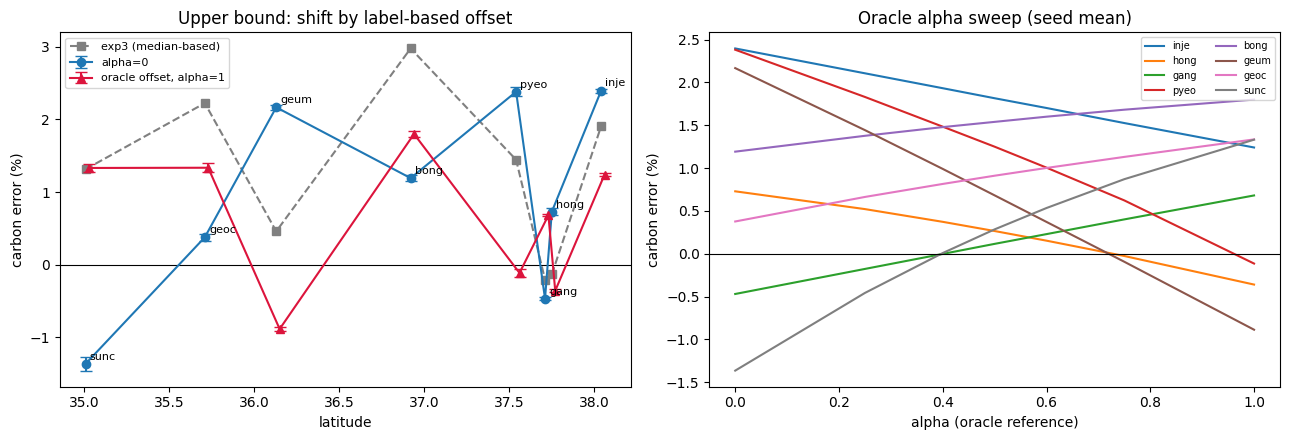

저장: exp4b_results.npz, exp4b_by_region.csv, exp4b_by_seed.csv, exp4b_upper.png
→ [7]–[9] 출력과 그림을 채팅에 붙여넣기


In [10]:
# [10] 그림·저장 (영문 표기)
lat = np.array([LAT[r] for r in TRAIN_REGIONS]); o = np.argsort(lat)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].axhline(0, c='k', lw=.8)
ax[0].errorbar(lat[o], E0.mean(0)[o], yerr=E0.std(0, ddof=1)[o], fmt='o-', capsize=4, label='alpha=0')
if EX3 is not None:
    ax[0].plot(lat[o], EX3.mean(0)[o], 's--', c='gray', label='exp3 (median-based)')
ax[0].errorbar(lat[o] + .02, EO.mean(0)[o], yerr=EO.std(0, ddof=1)[o], fmt='^-', c='crimson', capsize=4,
               label='oracle offset, alpha=1')
for k in o: ax[0].annotate(TRAIN_REGIONS[k][:4], (lat[k], E0.mean(0)[k]), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax[0].set_xlabel('latitude'); ax[0].set_ylabel('carbon error (%)'); ax[0].legend(fontsize=8)
ax[0].set_title('Upper bound: shift by label-based offset')
for j in range(nr):
    ax[1].plot(ALPHAS, CARB[:, j].mean(0), lw=1.5, label=TRAIN_REGIONS[j][:4])
ax[1].axhline(0, c='k', lw=.8); ax[1].set_xlabel('alpha (oracle reference)'); ax[1].set_ylabel('carbon error (%)')
ax[1].set_title('Oracle alpha sweep (seed mean)'); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f'{OUT}/exp4b_upper.png', dpi=150); plt.show()

tab.to_csv(f'{OUT}/exp4b_by_region.csv')
J.to_csv(f'{OUT}/exp4b_by_seed.csv', index=False)
print('저장: exp4b_results.npz, exp4b_by_region.csv, exp4b_by_seed.csv, exp4b_upper.png')
print('→ [7]–[9] 출력과 그림을 채팅에 붙여넣기')